In [2]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:40983")
client

<Client: 'tcp://127.0.0.1:40983' processes=12 threads=48, memory=755.54 GiB>

In [3]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [5]:
dsp = xr.open_zarr(op.join(ddir,"QG/eddy/qPsi.zarr"))
dsp

<xarray.Dataset> Size: 60GB
Dimensions:  (time: 718, level: 5, y: 1025, x: 2049)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.856e+09 1.858e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
  * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06
Data variables:
    pp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>
    qp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>

In [7]:
N2 = xr.DataArray(np.array([4.04e-05, 1.6e-05, 1.24e-05, 2.52e-06,]), 
                  dims="li",
                  coords={"li":np.array([0.5,1.5,2.5,3.5])}
                 )
dz = xr.DataArray(np.array([250,250,250,250,3000]), 
                  dims="level",
                  coords={"level":dsp.level.data}
                 )
Zp1 = np.concatenate((np.array([0.,]), -np.cumsum(dz.data)))
Z = .5*(Zp1[1:]+Zp1[:-1])
print(N2,Z,Zp1)

dsp["Zp1"] = xr.DataArray(Zp1, dims="lp1",
                          coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
                         )
dsp["Z"] = xr.DataArray(Z, dims="level",
                        coords={"level":dsp.level.data}
                       )
dsp["N2"] = N2

# llo, lla = np.meshgrid(dsp.x, dsp.y)
# xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
#                   coords={"y":dsp.y.data,
#                           "xG":.5*(dsp.x.data[1:]+dsp.x.data[:-1])}
#                  )
# yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
#                   coords={"yG":.5*(dsp.y.data[1:]+dsp.y.data[:-1]),
#                           "x":dsp.x.data}
#                  )
dsp.coords["yG"] = ("yG",.5*(dsp.y.data[1:]+dsp.y.data[:-1]))
dsp.coords["xG"] = ("xG",.5*(dsp.x.data[1:]+dsp.x.data[:-1]))

grid = Grid(dsp, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
            autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "outer": "lp1", "inner": "li"}
                   })

dsp, grid

<xarray.DataArray (li: 4)> Size: 32B
array([4.04e-05, 1.60e-05, 1.24e-05, 2.52e-06])
Coordinates:
  * li       (li) float64 32B 0.5 1.5 2.5 3.5 [ -125.  -375.  -625.  -875. -2500.] [    0.  -250.  -500.  -750. -1000. -4000.]


(<xarray.Dataset> Size: 60GB
 Dimensions:  (time: 718, level: 5, y: 1025, x: 2049, lp1: 6, li: 4, yG: 1024,
               xG: 2048)
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.856e+09 1.858e+09
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
   * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06
   * lp1      (lp1) float64 48B -0.5 0.5 1.5 2.5 3.5 4.5
   * li       (li) float64 32B 0.5 1.5 2.5 3.5
   * yG       (yG) float32 4kB 1.953e+03 5.859e+03 ... 3.994e+06 3.998e+06
   * xG       (xG) float32 8kB 1.953e+03 5.859e+03 ... 7.994e+06 7.998e+06
 Data variables:
     pp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>
     qp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>
     Zp1      (lp1) float64 48B 0.0 -250.0 -500.0 -750.0 -1e+03 -4e+03
     Z        (level) 

In [8]:
Delta = 3.90625e+03
up = -(grid.diff(dsp.pp.fillna(0.).chunk({"y":-1}),"Y",padding="extend") 
       / Delta)
vp = (grid.diff(dsp.pp.fillna(0.).chunk({"x":-1}),"X",padding="extend") 
      / Delta)
f0 = 7.3e-05
bp = (grid.diff(dsp.pp.fillna(0.).chunk({"level":-1}),
                "Z",padding="extend",to="inner")
      / grid.diff(dsp.Z,"Z",padding="extend",to="inner")
     ) * f0
up, vp, bp

(<xarray.DataArray 'pp' (time: 718, level: 5, yG: 1024, x: 2049)> Size: 30GB
 dask.array<neg, shape=(718, 5, 1024, 2049), dtype=float32, chunksize=(4, 1, 1024, 256), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.856e+09 1.858e+09
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * yG       (yG) float32 4kB 1.953e+03 5.859e+03 ... 3.994e+06 3.998e+06
   * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06,
 <xarray.DataArray 'pp' (time: 718, level: 5, y: 1025, xG: 2048)> Size: 30GB
 dask.array<truediv, shape=(718, 5, 1025, 2048), dtype=float32, chunksize=(4, 1, 125, 2048), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.856e+09 1.858e+09
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
   * xG       (xG) float32 8kB 1.953e+03 5.859e+03 ... 7.994e+06 7.998e+06,
 <xarray.DataArr

In [8]:
E00 = (up**2).mean("time")
Ediag = ((bp**2).mean("time") 
         / (2*N2))
E10 = (grid.interp(grid.interp(up.chunk({"x":-1}),
                               "X",boundary="extend").chunk({"yG":-1}),
                   "Y",boundary="extend")
       * vp
      ).mean("time")
E01 = (up 
       * grid.interp(grid.interp(vp.chunk({"xG":-1}),
                                 "X",boundary="extend").chunk({"y":-1}),
                     "Y",boundary="extend")
      ).mean("time")
E11 = (vp**2).mean("time")
E20 = -(grid.interp(grid.interp(vp.chunk({"xG":-1}),
                                "X",boundary="extend").chunk({"level":-1}),
                    "Z",boundary="extend",to="inner")
        * bp).mean("time") * f0/N2
E21 = (grid.interp(grid.interp(up.chunk({"yG":-1}),
                               "Y",boundary="extend").chunk({"level":-1}),
                   "Z",boundary="extend",to="inner")
       * bp).mean("time") * f0/N2

dsave = E00.to_dataset(name="E00")
dsave["Ediag"] = Ediag
dsave["E01"] = E01
dsave["E10"] = E10
dsave["E11"] = E11
dsave["E20"] = E20
dsave["E21"] = E21
print(dsave)
dsave.to_zarr(op.join(ddir,"QG/E-P.zarr"), mode="w")
dsave.close()

<xarray.Dataset> Size: 370MB
Dimensions:  (level: 5, x: 2049, yG: 1024, y: 1025, li: 4, xG: 2048)
Coordinates:
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06
  * yG       (yG) float32 4kB 1.953e+03 5.859e+03 ... 3.994e+06 3.998e+06
  * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
  * li       (li) float64 32B 0.5 1.5 2.5 3.5
  * xG       (xG) float32 8kB 1.953e+03 5.859e+03 ... 7.994e+06 7.998e+06
Data variables:
    E00      (level, yG, x) float32 42MB dask.array<chunksize=(1, 1024, 256), meta=np.ndarray>
    Ediag    (li, y, x) float64 67MB dask.array<chunksize=(4, 125, 256), meta=np.ndarray>
    E01      (level, yG, x) float32 42MB dask.array<chunksize=(1, 1024, 256), meta=np.ndarray>
    E10      (level, y, xG) float32 42MB dask.array<chunksize=(1, 125, 2048), meta=np.ndarray>
    E11      (level, y, xG) float32 42MB dask.array<chunksize=(1, 125, 2048), meta=np.ndarray>
    E20   

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 28.53 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [9]:
dsin = xr.open_dataset(op.join(ddir,"QG/input_vars_5l_N2048.nc")
                      ).isel(t=0)
dsin

<xarray.Dataset> Size: 34MB
Dimensions:     (y: 1025, x: 2049)
Coordinates:
  * y           (y) float32 4kB 0.0 1.0 2.0 ... 1.022e+03 1.023e+03 1.024e+03
  * x           (x) float32 8kB 0.0 1.0 2.0 ... 2.046e+03 2.047e+03 2.048e+03
    t           float32 4B 0.0
Data variables:
    ws_curl     (y, x) float32 8MB ...
    topo        (y, x) float32 8MB ...
    mask        (y, x) float32 8MB ...
    coastlines  (y, x) float32 8MB ...

In [10]:
mask = dsin.mask
try:
  mask0 = dsin.mask0
except:
  mask0 = dsin.coastlines

mask0_nan = np.where(mask0 == 0, np.nan, 1)
mask0_c_nan = mask0_nan[:-1,:-1]
mask0_nan, mask0_c_nan

(array([[ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        ...,
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.]], shape=(1025, 2049)),
 array([[ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        ...,
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.]], shape=(1024, 2048)))

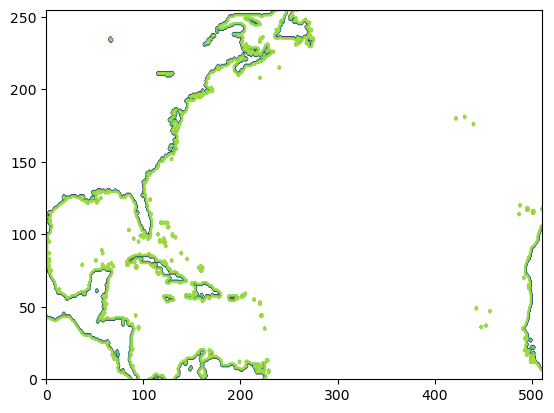

In [55]:
plt.contour(np.nan_to_num(mask0_c_nan)[::4,::4])

In [12]:
dsep = xr.open_zarr(op.join(ddir,"QG/E-P.zarr"))

gridp = Grid(dsep, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"},
             autoparse_metadata=False,
             coords={"X": {"center": "x", "inner": "xG"},
                     "Y": {"center": "y", "inner": "yG"},
                     "Z": {"center": "level", "inner": "li"}
                    }
            )

In [13]:
Fu0_x = gridp.interp(gridp.interp(gridp.diff(dsep.E00.chunk({"x":-1}), 
                                             "X", padding="extend")
                                  / Delta, 
                                  "X", padding="extend"
                                 ), 
                     "Y", padding="extend"
                    )
Fu0 = -(Fu0_x 
        + gridp.interp(gridp.interp(gridp.diff(dsep.E10.chunk({"y":-1}), 
                                               "Y", padding="extend")
                                    / Delta, 
                                    "Y", padding="extend"
                                   ), 
                       "X", padding="extend"
                      )
       ).fillna(0.)
Fu1 = -gridp.interp(gridp.diff(dsep.Ediag.chunk({"x":-1}), 
                               "X", padding="extend")
                    / Delta, 
                    "X", padding="extend"
                   ).fillna(0.)
Fu2 = -(gridp.diff(dsep.E20.chunk({"li":-1}), "Z", padding="extend"
                  ) / grid.diff(dsp.Zp1, "Z", padding="extend")
       ).fillna(0.)

Fv0_x = gridp.interp(gridp.interp(gridp.diff(dsep.E01.chunk({"x":-1}), 
                                             "X", padding="extend")
                                  / Delta, 
                                  "X", padding="extend"
                                 ), 
                     "Y", padding="extend"
                    )
Fv0 = -(Fv0_x 
        + gridp.interp(gridp.interp(gridp.diff(dsep.E11.chunk({"y":-1}), 
                                               "Y", padding="extend")
                                    / Delta,
                                    "Y", padding="extend"
                                   ),
                       "X", padding="extend"
                      )
       ).fillna(0.)
Fv1 = -gridp.interp(gridp.diff(dsep.Ediag.chunk({"y":-1}), 
                               "Y", padding="extend")
                    / Delta, 
                    "Y", padding="extend"
                   ).fillna(0.)
Fv2 = -(gridp.diff(dsep.E21.chunk({"li":-1}), "Z", padding="extend"
                  ) / grid.diff(dsp.Zp1, "Z", padding="extend")
       ).fillna(0.)

Fu0, Fu1, Fu2

(<xarray.DataArray (level: 5, y: 1025, x: 2049)> Size: 42MB
 dask.array<neg, shape=(5, 1025, 2049), dtype=float32, chunksize=(1, 1025, 2049), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
   * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06,
 <xarray.DataArray 'Ediag' (li: 4, y: 1025, x: 2049)> Size: 67MB
 dask.array<neg, shape=(4, 1025, 2049), dtype=float64, chunksize=(4, 125, 2049), chunktype=numpy.ndarray>
 Coordinates:
   * li       (li) float64 32B 0.5 1.5 2.5 3.5
   * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
   * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06,
 <xarray.DataArray (level: 5, y: 1025, x: 2049)> Size: 84MB
 dask.array<neg, shape=(5, 1025, 2049), dtype=float64, chunksize=(5, 125, 256), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  

In [15]:
Fu = (Fu0 
      + gridp.interp(Fu1.chunk({"li":-1}),"Z",padding="extend") + Fu2
     ).isel(level=slice(1,-1)).compute()
Fv = (Fv0 
      + gridp.interp(Fv1.chunk({"li":-1}),"Z",padding="extend") + Fv2
     ).isel(level=slice(1,-1)).compute()
Fu, Fv

(<xarray.DataArray (level: 3, y: 1025, x: 2049)> Size: 50MB
 array([[[ 0.00000000e+00,  2.95243214e-13, -6.16333373e-13, ...,
           0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
         [-3.40956159e-13, -9.60644717e-13, -5.86480231e-12, ...,
           0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
         [-1.37046028e-12, -5.26112051e-12, -2.21793114e-11, ...,
           0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
         ...,
         [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
           7.77445731e-14,  2.39224543e-14,  7.73788202e-15],
         [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
           2.35125621e-14,  5.27432205e-15,  2.26653862e-15],
         [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
           3.91502694e-15, -1.21213633e-15,  0.00000000e+00]],
 
        [[ 0.00000000e+00,  1.47997662e-13, -3.18464005e-13, ...,
           0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
         [-1.80390289e-13, 

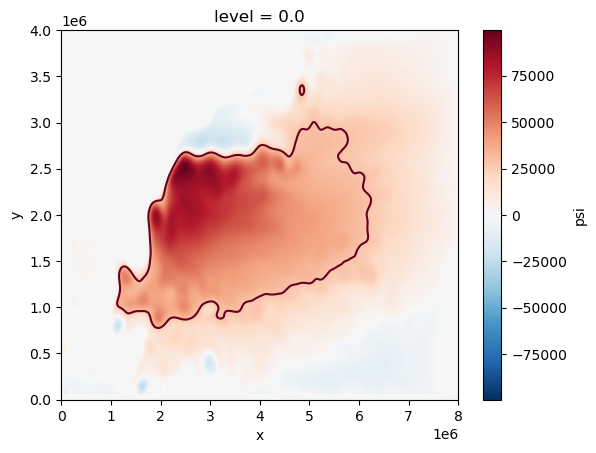

In [22]:
dsb = xr.open_zarr(op.join(ddir,"QG/mean/qPsi.zarr"))
dsb.psi.isel(level=0).plot(rasterized=True)
dsb.psi.isel(level=0).plot.contour(levels=np.array([2.84e4]))

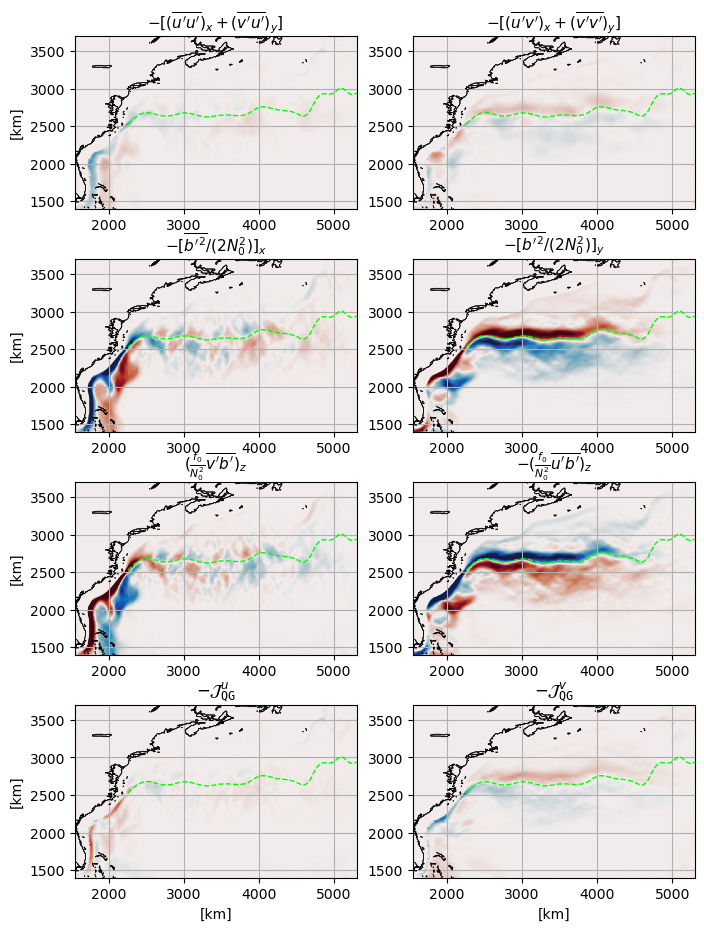

In [26]:
xmax = 5300
xmin = 1550
ymin = 1400
ymax = 3700

fig, axes = plt.subplots(figsize=(8,11.1), nrows=4, ncols=2)
# fig.set_tight_layout(True)
ax1 = axes[0,0]
ax2 = axes[1,0]
ax3 = axes[2,0]
ax4 = axes[3,0]
ax5 = axes[0,1]
ax6 = axes[1,1]
ax7 = axes[2,1]
ax8 = axes[3,1]
ax1.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax1.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax3.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax3.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax4.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax4.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax5.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax5.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax6.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax6.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax7.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax7.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax8.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax8.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
# ax1.coastlines(resolution='110m')
# ax2.coastlines(resolution='110m')
# ax3.coastlines(resolution='110m')
# ax4.coastlines(resolution='110m')
# ax5.coastlines(resolution='110m')
# ax6.coastlines(resolution='110m')
# ax7.coastlines(resolution='110m')
# ax8.coastlines(resolution='110m')
# gl1 = ax1.gridlines(draw_labels=True)
# gl1.top_labels = False
# gl1.right_labels = False
# gl2 = ax2.gridlines(draw_labels=True)
# gl2.top_labels = False
# gl2.right_labels = False
# gl3 = ax3.gridlines(draw_labels=True)
# gl3.top_labels = False
# gl3.right_labels = False
# gl4 = ax4.gridlines(draw_labels=True)
# gl4.top_labels = False
# gl4.right_labels = False
# gl5 = ax5.gridlines(draw_labels=True)
# gl5.top_labels = False
# gl5.right_labels = False
# gl6 = ax6.gridlines(draw_labels=True)
# gl6.top_labels = False
# gl6.right_labels = False
# gl7 = ax7.gridlines(draw_labels=True)
# gl7.top_labels = False
# gl7.right_labels = False
# gl8 = ax8.gridlines(draw_labels=True)
# gl8.top_labels = False
# gl8.right_labels = False

ax1.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               Fu0.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               zorder=0,
               # rasterized=True
              )
ax2.pcolormesh(dsp.x*1e-3, dsp.y*1e-3,
               gridp.interp(Fu1.chunk({"li":-1}), "Z",padding="extend"
                           ).isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               zorder=0,
               # rasterized=True
              )
ax3.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               Fu2.isel(level=1) , 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               zorder=0,
               # rasterized=True
              )
ax4.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               Fu.isel(level=0) , 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               zorder=0,
               # rasterized=True
              )

ax5.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               Fv0.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               zorder=0,
               # rasterized=True
              )
im = ax6.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               gridp.interp(Fv1.chunk({"li":-1}),"Z",padding="extend"
                           ).isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               zorder=0,
               # rasterized=True
                   )
ax7.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               Fv2.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               zorder=0,
               # rasterized=True
              )
ax8.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               Fv.isel(level=0), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               zorder=0,
               # rasterized=True
              )

ax1.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax2.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax3.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax4.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax5.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax6.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax7.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax8.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)

ax1.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax2.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax3.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax4.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax5.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax6.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax7.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax8.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax1.set_rasterized(True)
ax2.set_rasterized(True)
ax3.set_rasterized(True)
ax4.set_rasterized(True)
ax5.set_rasterized(True)
ax6.set_rasterized(True)
ax7.set_rasterized(True)
ax8.set_rasterized(True)

ax4.set_xlabel(r"[km]")
ax8.set_xlabel(r"[km]")
ax1.set_ylabel(r"[km]")
ax2.set_ylabel(r"[km]")
ax3.set_ylabel(r"[km]")
ax4.set_ylabel(r"[km]")
ax1.set_aspect("equal")
ax2.set_aspect("equal")
ax3.set_aspect("equal")
ax4.set_aspect("equal")
ax5.set_aspect("equal")
ax6.set_aspect("equal")
ax7.set_aspect("equal")
ax8.set_aspect("equal")
ax1.grid(True)
ax2.grid(True)
ax3.grid(True)
ax4.grid(True)
ax5.grid(True)
ax6.grid(True)
ax7.grid(True)
ax8.grid(True)

ax1.set_title(r"$-[(\overline{u'u'})_{x} + (\overline{v'u'})_{y}]$", 
              fontsize=11)
ax2.set_title(r"$-[\overline{{b'}^2}/(2N^2_0)]_{x}$", fontsize=11)
ax3.set_title(r"$(\frac{f_0}{N^2_0}\overline{v'b'})_{z}$", 
              fontsize=11)
ax4.set_title(r"$-\mathcal{J}^u_{\tt QG}$", fontsize=12)

ax5.set_title(r"$-[(\overline{u'v'})_{x} + (\overline{v'v'})_{y}]$", 
              fontsize=11)
ax6.set_title(r"$-[\overline{{b'}^2}/(2N^2_0)]_{y}$", fontsize=11)
ax7.set_title(r"$-(\frac{f_0}{N^2_0}\overline{u'b'})_{z}$", 
              fontsize=11)
ax8.set_title(r"$-\mathcal{J}^v_{\tt QG}$", fontsize=12)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/E-P_QG.pdf"), dpi=200)

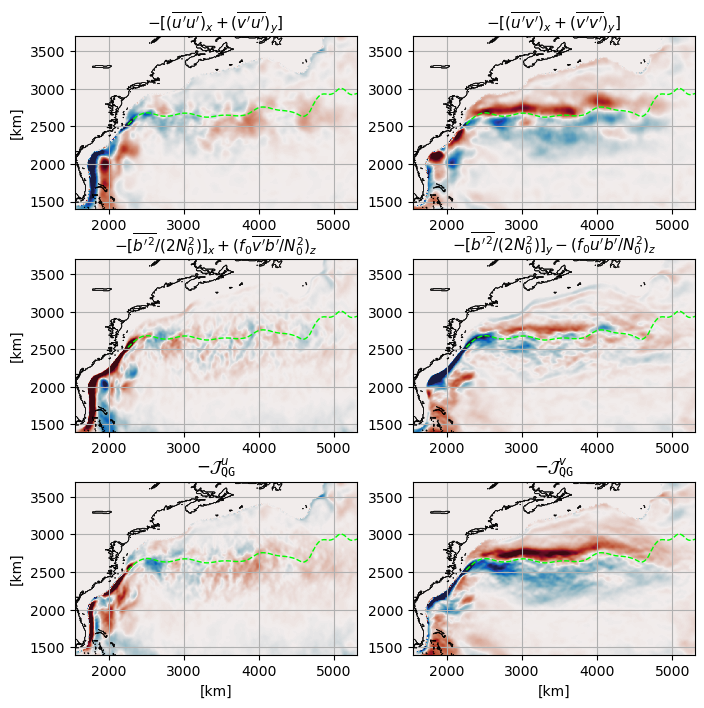

In [25]:
xmax = 5300
xmin = 1550
ymin = 1400
ymax = 3700

fig, axes = plt.subplots(figsize=(8,8.2), nrows=3, ncols=2)
# fig.set_tight_layout(True)
ax1 = axes[0,0]
# ax2 = axes[1,0]
ax3 = axes[1,0]
ax4 = axes[2,0]
ax5 = axes[0,1]
# ax6 = axes[1,1]
ax7 = axes[1,1]
ax8 = axes[2,1]
ax1.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax1.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
# ax2.set_xlim([xmin, xmax], 
#               # crs=ccrs.PlateCarree()
#               )
# ax2.set_ylim([ymin, ymax], 
#               # crs=ccrs.PlateCarree()
#               )
ax3.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax3.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax4.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax4.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax5.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax5.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
# ax6.set_xlim([xmin, xmax], 
#               # crs=ccrs.PlateCarree()
#               )
# ax6.set_ylim([ymin, ymax], 
#               # crs=ccrs.PlateCarree()
#               )
ax7.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax7.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax8.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax8.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
# ax1.coastlines(resolution='110m')
# ax2.coastlines(resolution='110m')
# ax3.coastlines(resolution='110m')
# ax4.coastlines(resolution='110m')
# ax5.coastlines(resolution='110m')
# ax6.coastlines(resolution='110m')
# ax7.coastlines(resolution='110m')
# ax8.coastlines(resolution='110m')
# gl1 = ax1.gridlines(draw_labels=True)
# gl1.top_labels = False
# gl1.right_labels = False
# gl2 = ax2.gridlines(draw_labels=True)
# gl2.top_labels = False
# gl2.right_labels = False
# gl3 = ax3.gridlines(draw_labels=True)
# gl3.top_labels = False
# gl3.right_labels = False
# gl4 = ax4.gridlines(draw_labels=True)
# gl4.top_labels = False
# gl4.right_labels = False
# gl5 = ax5.gridlines(draw_labels=True)
# gl5.top_labels = False
# gl5.right_labels = False
# gl6 = ax6.gridlines(draw_labels=True)
# gl6.top_labels = False
# gl6.right_labels = False
# gl7 = ax7.gridlines(draw_labels=True)
# gl7.top_labels = False
# gl7.right_labels = False
# gl8 = ax8.gridlines(draw_labels=True)
# gl8.top_labels = False
# gl8.right_labels = False

ax1.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               Fu0.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-.5e-6, vmax=.5e-6,
               zorder=0,
               # rasterized=True
              )
# ax2.pcolormesh(dsp.x*1e-3, dsp.y*1e-3,
#                gridp.interp(Fu1.chunk({"li":-1}), "Z",boundary="extend"
#                            ).isel(level=1) * mask0_nan, 
#                cmap=cmocean.cm.balance,
#                # cmap="RdBu_r",
#                vmin=-2.4e-6, vmax=2.4e-6,
#                zorder=0,
#                # rasterized=True
#               )
ax3.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               (Fu2.isel(level=1)
                + gridp.interp(Fu1.chunk({"li":-1}), "Z",padding="extend"
                              ).isel(level=1)), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-.5e-6, vmax=.5e-6,
               zorder=0,
               # rasterized=True
              )
ax4.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               Fu.isel(level=0), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-.5e-6, vmax=.5e-6,
               zorder=0,
               # rasterized=True
              )

ax5.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               Fv0.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-.5e-6, vmax=.5e-6,
               zorder=0,
               # rasterized=True
              )
# im = ax6.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
#                gridp.interp(Fv1.chunk({"li":-1}),"Z",boundary="extend"
#                            ).isel(level=1) * mask0_nan, 
#                cmap=cmocean.cm.balance,
#                # cmap="RdBu_r",
#                vmin=-2.4e-6, vmax=2.4e-6,
#                zorder=0,
#                # rasterized=True
#                    )
ax7.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               (Fv2.isel(level=1)
                + gridp.interp(Fv1.chunk({"li":-1}),"Z",padding="extend"
                              ).isel(level=1)), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-.5e-6, vmax=.5e-6,
               zorder=0,
               # rasterized=True
              )
ax8.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               Fv.isel(level=0), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-.5e-6, vmax=.5e-6,
               zorder=0,
               # rasterized=True
              )

ax1.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax3.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax4.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax5.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax7.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax8.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="lime", linestyles="dashed", linewidths=1)

ax1.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
# ax2.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
#             colors="k", linewidths=.2, zorder=10)
ax3.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax4.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax5.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
# ax6.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
#             colors="k", linewidths=.2, zorder=10)
ax7.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax8.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax1.set_rasterized(True)
# ax2.set_rasterized(True)
ax3.set_rasterized(True)
ax4.set_rasterized(True)
ax5.set_rasterized(True)
# ax6.set_rasterized(True)
ax7.set_rasterized(True)
ax8.set_rasterized(True)

ax4.set_xlabel(r"[km]")
ax8.set_xlabel(r"[km]")
ax1.set_ylabel(r"[km]")
# ax2.set_ylabel(r"[km]")
ax3.set_ylabel(r"[km]")
ax4.set_ylabel(r"[km]")
ax1.set_aspect("equal")
# ax2.set_aspect("equal")
ax3.set_aspect("equal")
ax4.set_aspect("equal")
ax5.set_aspect("equal")
# ax6.set_aspect("equal")
ax7.set_aspect("equal")
ax8.set_aspect("equal")
ax1.grid(True)
# ax2.grid(True)
ax3.grid(True)
ax4.grid(True)
ax5.grid(True)
# ax6.grid(True)
ax7.grid(True)
ax8.grid(True)

ax1.set_title(r"$-[(\overline{u'u'})_{x} + (\overline{v'u'})_{y}]$", 
              fontsize=11)
# ax2.set_title(r"$-[\overline{{b'}^2}/(2N^2_0)]_{x}$", fontsize=11)
ax3.set_title(r"$-[\overline{{b'}^2}/(2N^2_0)]_{x}+(f_0\overline{v'b'}/N^2_0)_{z}$", 
              fontsize=11)
ax4.set_title(r"$-\mathcal{J}^u_{\tt QG}$", fontsize=12)

ax5.set_title(r"$-[(\overline{u'v'})_{x} + (\overline{v'v'})_{y}]$", 
              fontsize=11)
# ax6.set_title(r"$-[\overline{{b'}^2}/(2N^2_0)]_{y}$", fontsize=11)
ax7.set_title(r"$-[\overline{{b'}^2}/(2N^2_0)]_{y}-(f_0\overline{u'b'}/N^2_0)_{z}$", 
              fontsize=11)
ax8.set_title(r"$-\mathcal{J}^v_{\tt QG}$", fontsize=12)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/E-P_QG_added.pdf"), dpi=200)

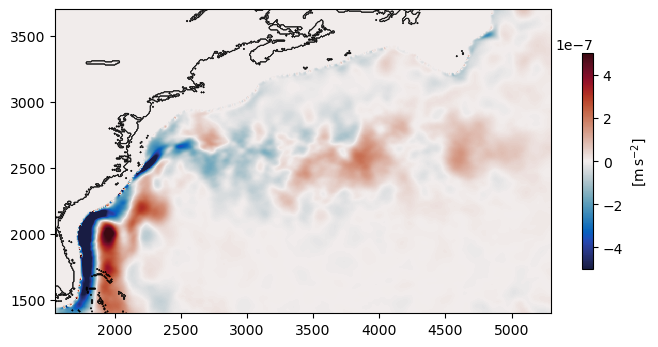

In [19]:
fig = plt.figure(figsize=(8,4))
ax6 = fig.add_subplot(1, 1, 1)
ax6.set_xlim([xmin, xmax], )
ax6.set_ylim([ymin, ymax], )

im = ax6.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               Fu0.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-.5e-6, vmax=.5e-6,
               rasterized=True)

ax6.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

cb = fig.colorbar(im, ax=ax6, shrink=.7)
cb.set_label(r"[m$\,$s$^{-2}$]")

ax6.set_rasterized(True)
ax6.set_aspect("equal")

plt.savefig(op.join(ddir,"Figs/E-P_QG_cbar.pdf"))